In [71]:
from pyomo.environ import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [72]:
from pyomo.environ import *
import numpy as np

model = ConcreteModel()

# === Universal Constants ===
model.R = Param(initialize=8.314, mutable=False)  # J mol⁻¹ K⁻¹
model.P = Param(initialize=101325.0, mutable=False)  # Pa (standard atmospheric pressure)
model.M_water = Param(initialize=0.01801528, mutable=False)  # kg mol⁻¹
model.psi_air = Param(initialize=-40e6, mutable=False)  # Pa, average air water potential (−40 MPa)

# === Environmental Parameters ===
model.T_air = Param(initialize=298.15, mutable=True)  # K (25°C)
model.RH = Param(initialize=0.8, mutable=True)  # Relative Humidity (fraction)
model.phi = Param(initialize=1000, mutable=True)  # W m⁻² (incident irradiance)

# === Physical Heat Transfer Parameters ===
model.gamma_mes = Param(initialize=0.01, mutable=True)  # W m⁻² K⁻¹ (mesophyll radiation coeff)
model.gamma_bs = Param(initialize=0.01, mutable=True)
model.gamma_soil = Param(initialize=0.01, mutable=True)
model.h_mes = Param(initialize=10.0, mutable=True)  # W m⁻² K⁻¹ (convective heat coeff)
model.h_soil = Param(initialize=5.0, mutable=True)
model.k_soil = Param(initialize=0.5, mutable=True)  # W m⁻¹ K⁻¹ (soil conductivity)
model.d_soil = Param(initialize=0.5, mutable=True)  # m (soil depth)
model.kappa = Param(initialize=2.6e6, mutable=True)  # J kg⁻¹ (latent heat of vaporization)
model.C_w = Param(initialize=4184, mutable=True)  # J kg⁻¹ K⁻¹ (specific heat of water)

# === Light Partitioning Coefficients ===
model.alpha_mes = Param(initialize=0.5, mutable=True)
model.alpha_bs = Param(initialize=0.6, mutable=True)
model.alpha_surf = Param(initialize=0.7, mutable=True)
model.tau_mes = Param(initialize=0.4, mutable=True)
model.tau_bs = Param(initialize=0.4, mutable=True)
model.zeta = Param(initialize=0.85, mutable=True)

# === Surface Areas and Conductances ===
model.A_mes = Param(initialize=2.5, mutable=True)  # m²
model.A_bs = Param(initialize=1.5, mutable=True)
model.A_contact = Param(initialize=0.5, mutable=True)
model.U_mes_bs = Param(initialize=50.0, mutable=True)  # W m⁻² K⁻¹
model.A_circ = Param(initialize=0.6, mutable=True)

model.g_m = Param(initialize=1e-5, mutable=False)  # mol m⁻² s⁻¹ Pa⁻¹
model.g_soil = Param(initialize=1e-4, mutable=False)
model.g_bs = Param(initialize=1e-4, mutable=False)

# === PEPC / Rubisco Kinetics Parameters ===
model.Vpmax_25 = Param(initialize=200e-6, mutable=False)
model.Ea_Vpmax = Param(initialize=50100, mutable=False)
model.DS_Vpmax = Param(initialize=250, mutable=False)
model.Hd_Vpmax = Param(initialize=73300, mutable=False)

# === Soil Evaporation ===
model.E_soil = Param(initialize=1.11e-5, mutable=False)  # kg s⁻¹ m⁻²

# === Decision Variables ===
model.g_s = Var(bounds=(1e-8, 1e-2), initialize=1e-6)
model.F = Var(bounds=(0, 10.0), initialize=0.01)
model.T_mes = Var(bounds=(290, 340), initialize=300)
model.T_bs = Var(bounds=(290, 340), initialize=300)
model.T_soil = Var(bounds=(290, 340), initialize=300)
model.psi_soil = Var(bounds=(-1e7, 0.0), initialize=-3e6)
model.psi_bs = Var(bounds=(-2e6, 0.0), initialize=-5e5)
model.psi_mes = Var(bounds=(-3e6, 0.0), initialize=-1e6)

# === Helper Constants for VPD Calculation ===
SATURATION_VP_COEFF = 0.6108e3  # Pa
VPD_A = 17.27
VPD_B = 237.3

# === Expressions ===

# Effective leaf-air conductance
model.g_air = Expression(expr=1 / (1 / model.g_s + 1 / model.g_m))

# Vapor pressure deficit (VPD, Pa)
model.VPD = Expression(expr=SATURATION_VP_COEFF * exp(
    VPD_A * (model.T_air - 273.15) / (model.T_air - 273.15 + VPD_B)) * (1 - model.RH)
)

# Transpiration rate (E_mes, kg s⁻¹ m⁻²)
model.E_mes = Expression(expr=model.g_air * model.VPD / model.P * (1 / model.M_water))

# Light Absorption by compartments
model.phi_mes = Expression(expr=model.alpha_mes * model.phi * model.zeta)
model.phi_bs = Expression(expr=model.alpha_bs * model.tau_mes * model.phi * model.zeta)
model.phi_soil = Expression(expr=model.alpha_surf *
                            ((model.zeta * model.tau_bs * model.tau_mes) + (1 - model.zeta)) * model.phi)
model.total_absorbed = Expression(expr=model.phi_mes + model.phi_bs + model.phi_soil)

# Cooling components
model.z = Expression(expr=model.zeta)
model.rad_mes = Expression(expr=model.gamma_mes * model.T_mes * model.z * model.A_mes)
model.conv_mes = Expression(expr=model.h_mes * (model.T_mes - model.T_air) * model.z * model.A_mes)
model.cond_mesbs = Expression(expr=model.U_mes_bs * (model.T_mes - model.T_bs) * model.z * model.A_contact)

model.rad_bs = Expression(expr=model.gamma_bs * model.T_bs * model.z * model.A_bs)
model.circular_flow = Expression(expr=model.C_w * model.F * (model.T_bs - model.T_soil) * model.A_circ)

model.beta_soil = Expression(expr=model.h_soil + model.k_soil / model.d_soil)
model.rad_soil = Expression(expr=model.gamma_soil * model.T_soil)
model.conv_soil = Expression(expr=model.h_soil * (model.T_soil - model.T_air))
model.cond_soil_air = Expression(expr=model.beta_soil * (model.T_soil - model.T_air))

model.transp_mes = Expression(expr=model.kappa * model.E_mes)
model.evap_soil = Expression(expr=model.kappa * model.E_soil)

# PEPC assimilation rate (T_mes dependent)
model.A_pepc = Expression(expr=model.Vpmax_25 * exp(
    model.Ea_Vpmax * (model.T_mes - 298.15) / (298.15 * model.R * model.T_mes)) *
    ((1 + exp((298.15 * model.DS_Vpmax - model.Hd_Vpmax) / (298.15 * model.R))) /
     (1 + exp((model.T_mes * model.DS_Vpmax - model.Hd_Vpmax) / (model.T_mes * model.R))))
)

# Rubisco assimilation rate (T_bs dependent)
model.A_rub = Expression(expr=model.Vpmax_25 * exp(
    model.Ea_Vpmax * (model.T_bs - 298.15) / (298.15 * model.R * model.T_bs)) *
    ((1 + exp((298.15 * model.DS_Vpmax - model.Hd_Vpmax) / (298.15 * model.R))) /
     (1 + exp((model.T_bs * model.DS_Vpmax - model.Hd_Vpmax) / (model.T_bs * model.R))))
)

# === Energy Balance Constraints ===
model.energy_mes = Constraint(expr=model.phi_mes - model.rad_mes - model.conv_mes - model.cond_mesbs - model.transp_mes == 0)
model.energy_bs = Constraint(expr=model.phi_bs - model.rad_bs + model.cond_mesbs - model.circular_flow == 0)
model.energy_soil = Constraint(expr=model.phi_soil - model.rad_soil - model.cond_soil_air - model.evap_soil + model.circular_flow == 0)

# === Water Potential Balance Constraints ===
model.hydro_mes = Constraint(expr=model.g_bs * (model.psi_bs - model.psi_mes) -
                             model.g_s * (model.psi_mes - model.psi_air) == 0)

model.hydro_bs = Constraint(expr=model.g_soil * (model.psi_soil - model.psi_bs) -
                            model.g_bs * (model.psi_bs - model.psi_mes) - model.F == 0)

# === Transpiration Bound Constraint ===
model.transp_limit = Constraint(expr=model.E_mes <= model.g_soil * abs(model.psi_soil))

# === Objective: Maximize total carbon assimilation ===
model.objective = Objective(expr=model.A_pepc + model.A_rub, sense=maximize)


## solving strategy

model.name="unknown";
    - termination condition: infeasible
    - message from solver: Ipopt 3.14.10\x3a Converged to a locally infeasible
      point. Problem may be infeasible.


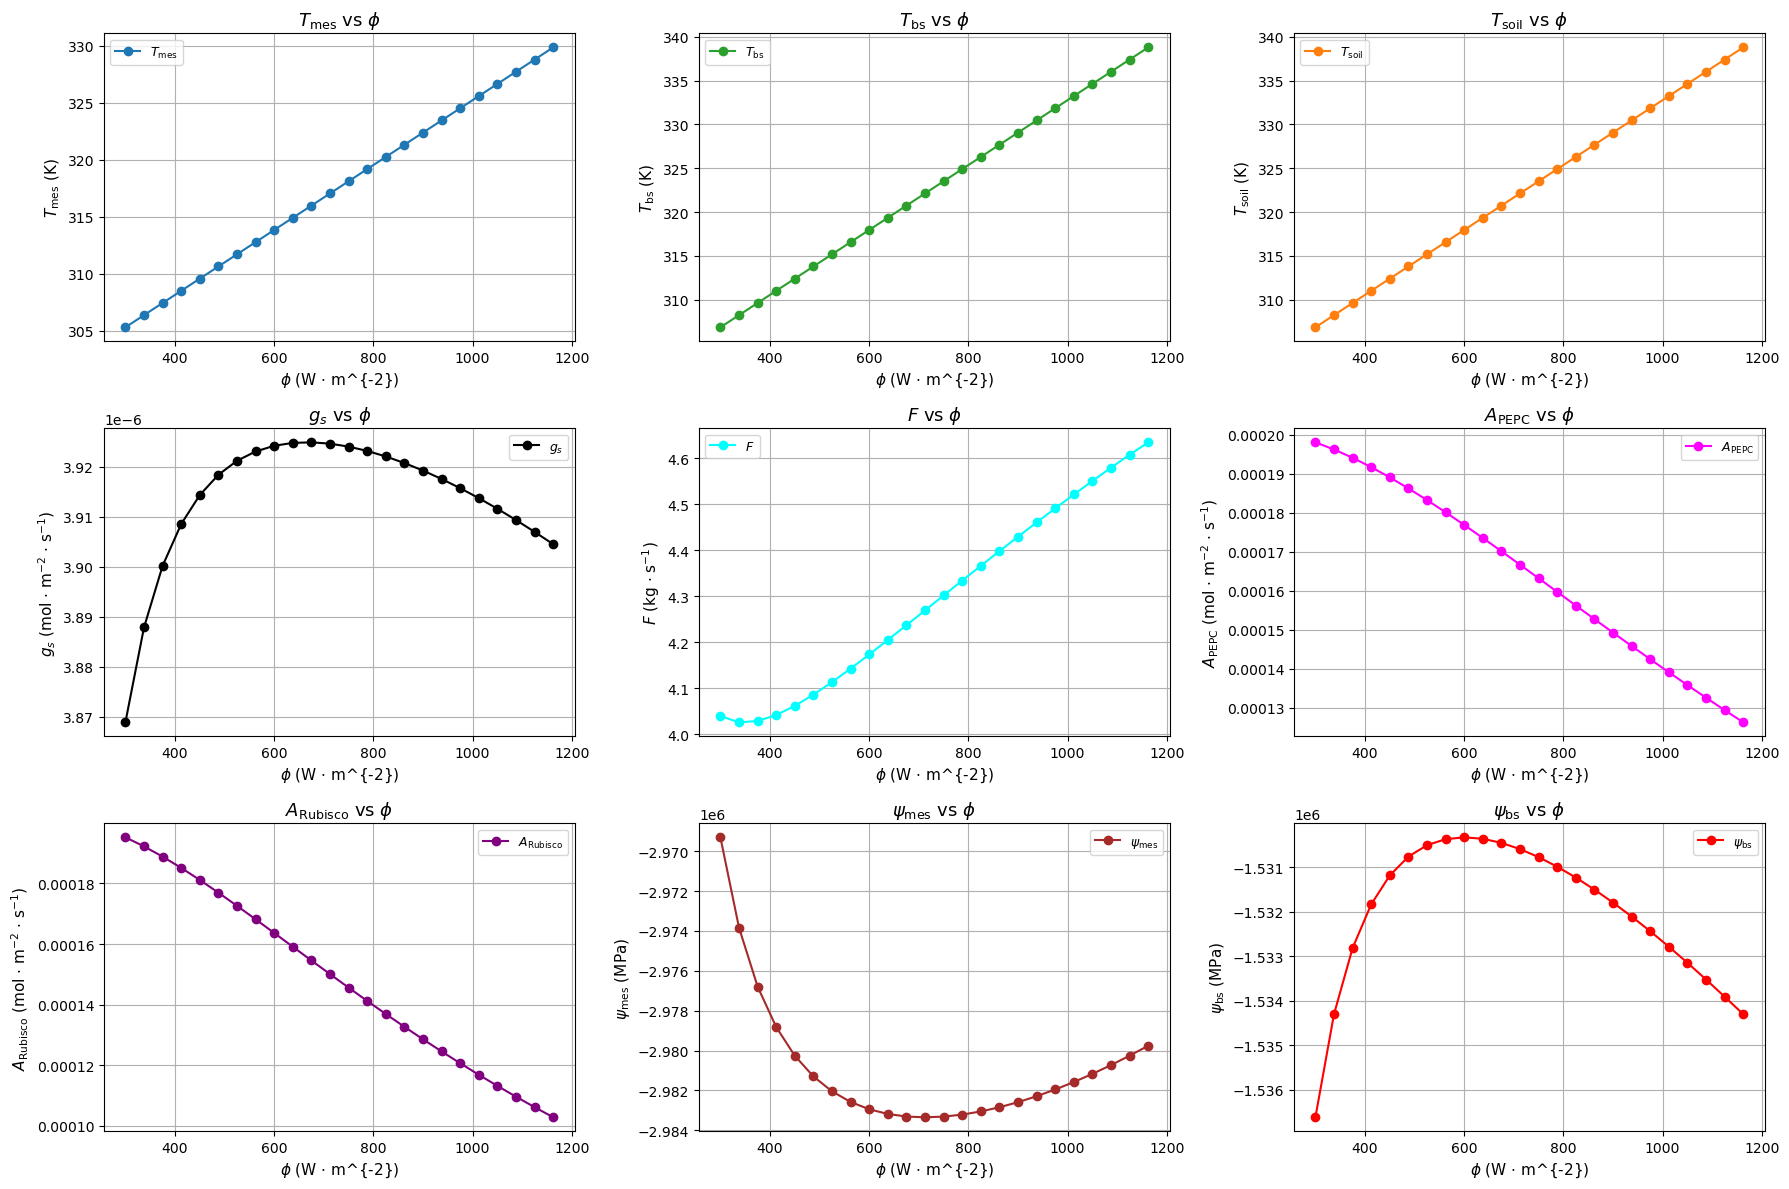

In [73]:



# === Model Solver ===
def solve_model(param_updates=None):
    if param_updates:
        for k, v in param_updates.items():
            if hasattr(model, k):
                getattr(model, k).set_value(v)
    solver = SolverFactory("ipopt")
    result = solver.solve(model, tee=False)
    if (result.solver.status != SolverStatus.ok) or (result.solver.termination_condition != TerminationCondition.optimal):
        return [np.nan] * 9
    return [
        value(model.T_mes),
        value(model.T_bs),
        value(model.T_soil),
        value(model.g_s),
        value(model.F),
        value(model.A_pepc),
        value(model.A_rub),
        value(model.psi_mes),
        value(model.psi_bs),
    ]


# === Parameter Sweep ===
def sweep_one_param(param_name, values):
    results = []
    for val in values:
        results.append(solve_model({param_name: val}))
    return np.array(results)


# === Sweep Execution ===
phi_values = np.linspace(300, 1200, 25)
results = sweep_one_param("phi", phi_values)

# Unpack results
T_mes_vals, T_bs_vals, T_soil_vals = results[:, 0], results[:, 1], results[:, 2]
g_s_vals, F_vals = results[:, 3], results[:, 4]
A_pepc_vals, A_rub_vals = results[:, 5], results[:, 6]
psi_mes_vals, psi_bs_vals = results[:, 7], results[:, 8]

# === Plotting ===
titles = [
    r"$T_{\mathrm{mes}}$ vs $\phi$", r"$T_{\mathrm{bs}}$ vs $\phi$", r"$T_{\mathrm{soil}}$ vs $\phi$",
    r"$g_s$ vs $\phi$", r"$F$ vs $\phi$", r"$A_{\mathrm{PEPC}}$ vs $\phi$",
    r"$A_{\mathrm{Rubisco}}$ vs $\phi$", r"$\psi_{\mathrm{mes}}$ vs $\phi$", r"$\psi_{\mathrm{bs}}$ vs $\phi$"
]
ylabels = [
    r"$T_{\mathrm{mes}}$ (K)", r"$T_{\mathrm{bs}}$ (K)", r"$T_{\mathrm{soil}}$ (K)",
    r"$g_s$ (mol $\cdot$ m$^{-2}$ $\cdot$ s$^{-1}$)", r"$F$ (kg $\cdot$ s$^{-1}$)", r"$A_{\mathrm{PEPC}}$ (mol $\cdot$ m$^{-2}$ $\cdot$ s$^{-1}$)",
    r"$A_{\mathrm{Rubisco}}$ (mol $\cdot$ m$^{-2}$ $\cdot$ s$^{-1}$)", r"$\psi_{\mathrm{mes}}$ (MPa)", r"$\psi_{\mathrm{bs}}$ (MPa)"
]
data = [T_mes_vals, T_bs_vals, T_soil_vals, g_s_vals, F_vals, A_pepc_vals, A_rub_vals, psi_mes_vals, psi_bs_vals]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'black', 'cyan', 'magenta', 'purple', 'brown', 'red']

fig, axs = plt.subplots(3, 3, figsize=(18, 12))
axs = axs.ravel()

for i in range(9):
    axs[i].plot(phi_values, data[i], marker='o', linestyle='-', color=colors[i], label=titles[i].split()[0])
    axs[i].set_title(titles[i], fontsize=13)
    axs[i].set_ylabel(ylabels[i], fontsize=11)
    axs[i].set_xlabel(r"$\phi$ (W $\cdot$ m^{-2})", fontsize=11)
    axs[i].legend(loc="best", fontsize=9)
    axs[i].grid(True)

plt.tight_layout()
plt.show()
